<a href="https://colab.research.google.com/github/AhmadSelao180874/LSTM_Perbandingan-Model/blob/main/Salinan_dari_Pipeline_Terintegrasi_5Model_Baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline Terintegrasi: Custom CNN vs MobileNetV2 vs VGG16 vs YOLOv8-cls
## Klasifikasi Biner Limbah Plastik Pesisir — Citra Sentinel-2A True-Color

**Integrasi dari notebook `Latih_ModelYolo_MNetV2.ipynb`**, dirapikan dan disatukan agar:
1. **Split data train/val SAMA** dipakai untuk ketiga model → perbandingan performa jadi adil (apple-to-apple)
2. **Error handling eksplisit** di setiap tahap kritis (load CSV, konversi gambar, split, training) — gagal cepat dengan pesan jelas, bukan traceback mentah di tengah proses
3. **Augmentasi konsisten** diterapkan ke ketiga model dengan intensitas yang wajar untuk citra true-color
4. **Tidak ada duplikasi cell** — setiap tahap konversi/split hanya dijalankan sekali

**Struktur pipeline:**
1. Setup & Konfigurasi
2. Load & Validasi Dataset (CSV + Gambar)
3. Konversi TIF → PNG (idempoten, sekali jalan)
4. Split Data (stratified) + Oversampling Kelas Minoritas
5. Data Generator (augmentasi) untuk Custom CNN & MobileNetV2
6. Model 1: Custom CNN
7. Model 2: MobileNetV2 (Transfer Learning)
8. Model 3: VGG16 (Transfer Learning)
9. Model 4: YOLOv8-cls
10. Evaluasi & Perbandingan Keempat Model (+ Safeguard Anti-Bug)
11. Ringkasan


## 1. Setup & Konfigurasi

In [ ]:

# ==========================================
# IMPORTS
# ==========================================
import os
import sys
import shutil
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, regularizers
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
    from tensorflow.keras.applications import MobileNetV2, VGG16
    from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
    from tensorflow.keras.models import Model
    from tensorflow.keras.optimizers import Adam
except ImportError as e:
    raise ImportError(
        f"TensorFlow/Keras tidak ditemukan atau gagal diimpor: {e}. "
        f"Install dengan: pip install tensorflow --break-system-packages"
    ) from e

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
from sklearn.utils.class_weight import compute_class_weight


def setup_logging():
    """Logger konsisten untuk seluruh pipeline -- tampil di console + tersimpan ke file."""
    logger = logging.getLogger("plastik_pipeline")
    logger.setLevel(logging.INFO)
    logger.handlers.clear()
    fmt = logging.Formatter("[%(asctime)s] %(levelname)s: %(message)s", datefmt="%H:%M:%S")

    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    logger.addHandler(sh)

    try:
        fh = logging.FileHandler("pipeline_log.txt", mode="a", encoding="utf-8")
        fh.setFormatter(fmt)
        logger.addHandler(fh)
    except OSError as e:
        print(f"PERINGATAN: gagal membuat file log: {e}. Lanjut dengan console logging saja.")

    return logger

logger = setup_logging()
logger.info("Logger siap. Memulai pipeline training terintegrasi.")


[22:11:31] INFO: Logger siap. Memulai pipeline training terintegrasi.


INFO:plastik_pipeline:Logger siap. Memulai pipeline training terintegrasi.


In [ ]:

# ==========================================
# MOUNT GOOGLE DRIVE (khusus Colab) -- aman dijalankan berulang
# ==========================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
    logger.info("Google Drive berhasil di-mount.")
except ImportError:
    logger.warning(
        "Modul 'google.colab' tidak ditemukan -- sepertinya bukan berjalan di Colab. "
        "Pastikan path CONFIG di bawah disesuaikan dengan environment lokal Anda."
    )
except Exception as e:
    logger.error(f"Gagal mount Google Drive: {e}")
    raise


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[22:11:32] INFO: Google Drive berhasil di-mount.


INFO:plastik_pipeline:Google Drive berhasil di-mount.


In [ ]:

# ==========================================
# CEK GPU -- WARNING JELAS JIKA TIDAK ADA GPU
# ==========================================
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    logger.info(f"GPU terdeteksi: {gpu_devices}")
else:
    logger.warning(
        "TIDAK ADA GPU terdeteksi (GPU Available: []). "
        "Training akan SANGAT LAMBAT, terutama untuk MobileNetV2. "
        "Di Colab: Runtime > Change runtime type > pilih GPU (T4), lalu restart runtime."
    )


[22:11:32] WARNING: TIDAK ADA GPU terdeteksi (GPU Available: []). Training akan SANGAT LAMBAT, terutama untuk MobileNetV2. Di Colab: Runtime > Change runtime type > pilih GPU (T4), lalu restart runtime.


In [ ]:

# ==========================================
# KONFIGURASI GLOBAL -- SESUAIKAN DENGAN SETUP AHMAD
# ==========================================
CONFIG = {
    # --- Path & data ---
    "csv_path": "/content/drive/MyDrive/project_BIMA26/layer_gabungfix_parebarrumakassar28426.csv",
    "images_dir_raw": "/content/drive/MyDrive/project_BIMA26/outputgbg_paremakassar28426_png_rasterio",
    "images_dir_png": "/content/drive/MyDrive/project_BIMA26/outputgbg_paremakassar28426_png_rasterio",  # diperbarui otomatis jika konversi dijalankan
    "x_col": "Patch_ID",
    "y_col": "Jenis_Obyek",
    "class_names": ["non_plastik", "plastik"],  # urutan konsisten dipakai di semua model
    "minority_class": "plastik",

    # --- Split ---
    "test_size": 0.2,
    "random_state": 42,

    # --- Training umum (Custom CNN & MobileNetV2) ---
    "img_size": (32, 32),
    "batch_size": 16,
    "epochs": 50,

    # --- YOLOv8-cls ---
    "yolo_dataset_dir": "/content/drive/MyDrive/project_BIMA26/yolov8_dataset_integrated",
    "yolo_model_arch": "yolov8n-cls.pt",
    "yolo_epochs": 60,
    "yolo_imgsz": 32,       # disesuaikan dengan resolusi asli citra (patch kecil)
    "yolo_batch": 16,
    "yolo_lr0": 0.001,
    "yolo_lrf": 0.01,
    "yolo_patience": 15,

    # --- Output ---
    "save_dir": "/content/drive/MyDrive/project_BIMA26/model_comparison_outputs",
}

os.makedirs(CONFIG["save_dir"], exist_ok=True)
logger.info("CONFIG berhasil didefinisikan. Sesuaikan path di atas jika struktur folder Anda berbeda.")


[22:11:32] INFO: CONFIG berhasil didefinisikan. Sesuaikan path di atas jika struktur folder Anda berbeda.


INFO:plastik_pipeline:CONFIG berhasil didefinisikan. Sesuaikan path di atas jika struktur folder Anda berbeda.


## 2. Load & Validasi Dataset (CSV + Gambar)

In [ ]:

def load_and_validate_csv(config: dict, logger: logging.Logger) -> pd.DataFrame:
    """
    Load CSV dan validasi kolom wajib + normalisasi ekstensi file ke .png.

    Raises:
        FileNotFoundError: jika file CSV tidak ditemukan
        KeyError: jika kolom X_COL / Y_COL tidak ada di CSV
        ValueError: jika CSV kosong atau class_names tidak cocok dengan isi Y_COL
    """
    csv_path = config["csv_path"]
    if not os.path.exists(csv_path):
        raise FileNotFoundError(
            f"File CSV tidak ditemukan di '{csv_path}'. "
            f"Periksa kembali path di CONFIG['csv_path'] dan pastikan Drive sudah ter-mount."
        )

    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        raise ValueError(f"Gagal membaca CSV '{csv_path}': {type(e).__name__}: {e}") from e

    if df.empty:
        raise ValueError(f"CSV '{csv_path}' berhasil dibaca tapi kosong (0 baris).")

    x_col, y_col = config["x_col"], config["y_col"]
    missing_cols = [c for c in (x_col, y_col) if c not in df.columns]
    if missing_cols:
        raise KeyError(
            f"Kolom wajib {missing_cols} tidak ditemukan di CSV. "
            f"Kolom yang tersedia: {df.columns.tolist()}. "
            f"Perbarui CONFIG['x_col']/CONFIG['y_col'] agar sesuai."
        )

    # Normalisasi ekstensi .tif -> .png di kolom nama file
    df[x_col] = df[x_col].apply(
        lambda f: f[:-4] + '.png' if isinstance(f, str) and f.lower().endswith('.tif') else f
    )

    unexpected_classes = set(df[y_col].unique()) - set(config["class_names"])
    if unexpected_classes:
        raise ValueError(
            f"Ditemukan kelas tak terduga di kolom '{y_col}': {unexpected_classes}. "
            f"Kelas yang diharapkan: {config['class_names']}. "
            f"Perbarui CONFIG['class_names'] atau periksa data mentah."
        )

    logger.info(f"CSV berhasil dimuat: {len(df)} baris.")
    logger.info(f"Distribusi kelas:\n{df[y_col].value_counts().to_string()}")
    return df


def validate_images_exist(df: pd.DataFrame, images_dir: str, x_col: str, logger: logging.Logger,
                            sample_check: bool = True) -> None:
    """
    Validasi bahwa direktori gambar ada dan berisi file yang direferensikan CSV.
    Jika sample_check=True, hanya cek subset acak (lebih cepat untuk dataset besar).

    Raises:
        FileNotFoundError: jika direktori tidak ada, atau proporsi file hilang terlalu tinggi
    """
    if not os.path.isdir(images_dir):
        raise FileNotFoundError(
            f"Direktori gambar tidak ditemukan: '{images_dir}'. "
            f"Periksa CONFIG['images_dir_raw'] / CONFIG['images_dir_png']."
        )

    check_df = df.sample(min(50, len(df)), random_state=42) if sample_check else df
    missing = [f for f in check_df[x_col] if not os.path.exists(os.path.join(images_dir, f))]

    missing_ratio = len(missing) / len(check_df)
    if missing_ratio > 0.5:
        raise FileNotFoundError(
            f"{len(missing)}/{len(check_df)} file gambar sampel TIDAK ditemukan di '{images_dir}'. "
            f"Contoh file hilang: {missing[:5]}. "
            f"Kemungkinan: (1) ekstensi file belum dikonversi (masih .tif), "
            f"(2) IMAGES_DIR menunjuk ke folder yang salah."
        )
    elif missing:
        logger.warning(f"{len(missing)}/{len(check_df)} file sampel tidak ditemukan -- lanjut, tapi periksa data.")
    else:
        logger.info(f"Validasi gambar OK: sampel {len(check_df)} file semuanya ditemukan di '{images_dir}'.")


df = load_and_validate_csv(CONFIG, logger)
validate_images_exist(df, CONFIG["images_dir_raw"], CONFIG["x_col"], logger)


[22:11:32] INFO: CSV berhasil dimuat: 385 baris.


INFO:plastik_pipeline:CSV berhasil dimuat: 385 baris.


[22:11:32] INFO: Distribusi kelas:
Jenis_Obyek
non_plastik    212
plastik        173


INFO:plastik_pipeline:Distribusi kelas:
Jenis_Obyek
non_plastik    212
plastik        173


[22:11:32] INFO: Validasi gambar OK: sampel 50 file semuanya ditemukan di '/content/drive/MyDrive/project_BIMA26/outputgbg_paremakassar28426_png_rasterio'.


INFO:plastik_pipeline:Validasi gambar OK: sampel 50 file semuanya ditemukan di '/content/drive/MyDrive/project_BIMA26/outputgbg_paremakassar28426_png_rasterio'.


## 3. Konversi TIF → PNG (Idempoten)

Fungsi ini **aman dijalankan berkali-kali** — file yang sudah dikonversi otomatis dilewati (skip), tidak seperti notebook asli yang menjalankan blok konversi 3× secara terpisah.

In [ ]:

def convert_tif_to_png(images_dir_raw: str, images_dir_png: str, df: pd.DataFrame, x_col: str,
                        logger: logging.Logger) -> str:
    """
    Konversi .tif -> .png satu kali, skip file yang sudah ada.
    Coba pakai rasterio dulu (lebih robust untuk GeoTIFF multiband), fallback ke PIL.

    Returns:
        str: path direktori PNG final (untuk update CONFIG['images_dir_png'])

    Raises:
        RuntimeError: jika SEMUA file gagal dikonversi (bukan sebagian)
    """
    os.makedirs(images_dir_png, exist_ok=True)

    try:
        import rasterio
        use_rasterio = True
    except ImportError:
        logger.warning("Library 'rasterio' tidak tersedia, fallback ke PIL untuk konversi.")
        use_rasterio = False

    from PIL import Image

    converted, skipped, failed = 0, 0, 0
    failed_files = []

    for _, row in df.iterrows():
        raw_name = row[x_col]
        if not isinstance(raw_name, str):
            continue
        tif_name = raw_name.replace('.png', '.tif') if raw_name.lower().endswith('.png') else raw_name
        png_name = tif_name.replace('.tif', '.png') if tif_name.lower().endswith('.tif') else tif_name

        src_path = os.path.join(images_dir_raw, tif_name)
        dst_path = os.path.join(images_dir_png, png_name)

        if os.path.exists(dst_path):
            skipped += 1
            continue
        if not os.path.exists(src_path):
            failed += 1
            failed_files.append(tif_name)
            continue

        try:
            if use_rasterio:
                with rasterio.open(src_path) as src:
                    arr = src.read()
                    arr = np.transpose(arr, (1, 2, 0)) if arr.ndim == 3 else arr
                    if arr.dtype != np.uint8:
                        arr = ((arr - arr.min()) / (arr.max() - arr.min() + 1e-9) * 255).astype(np.uint8)
                    Image.fromarray(arr[:, :, :3] if arr.shape[-1] >= 3 else arr.squeeze()).save(dst_path, 'PNG')
            else:
                with Image.open(src_path) as img:
                    img.save(dst_path, 'PNG')
            converted += 1
        except Exception as e:
            failed += 1
            failed_files.append(f"{tif_name} ({type(e).__name__}: {e})")

    logger.info(f"Konversi TIF->PNG selesai. Berhasil: {converted}, sudah ada (skip): {skipped}, gagal: {failed}")
    if failed_files:
        logger.warning(f"Contoh file gagal/hilang: {failed_files[:5]}")

    if converted == 0 and skipped == 0:
        raise RuntimeError(
            f"SEMUA {failed} file gagal dikonversi. Periksa apakah '{images_dir_raw}' berisi file yang benar."
        )

    return images_dir_png


# Jalankan konversi hanya jika folder PNG target belum berisi cukup file
_png_dir = CONFIG["images_dir_png"]
_existing_png_count = len([f for f in os.listdir(_png_dir) if f.lower().endswith('.png')]) if os.path.isdir(_png_dir) else 0

if _existing_png_count >= len(df) * 0.9:
    logger.info(f"Folder PNG sudah berisi {_existing_png_count} file (>=90% dataset) -- lewati konversi.")
else:
    CONFIG["images_dir_png"] = convert_tif_to_png(
        CONFIG["images_dir_raw"], CONFIG["images_dir_png"], df, CONFIG["x_col"], logger
    )

# Pastikan kolom X_COL di df memakai ekstensi .png untuk semua tahap selanjutnya
df[CONFIG["x_col"]] = df[CONFIG["x_col"]].str.replace('.tif', '.png', regex=False)
IMAGES_DIR = CONFIG["images_dir_png"]


[22:11:32] INFO: Folder PNG sudah berisi 381 file (>=90% dataset) -- lewati konversi.


INFO:plastik_pipeline:Folder PNG sudah berisi 381 file (>=90% dataset) -- lewati konversi.


## 4. Split Data (Stratified) + Oversampling Kelas Minoritas

**Penting:** split ini (`df_train` / `df_val`) dipakai untuk **ketiga model** (Custom CNN, MobileNetV2, DAN YOLOv8-cls) — bukan split terpisah seperti di notebook asli — agar perbandingan akurasi antar model benar-benar adil (data validasi identik).

In [ ]:

def split_and_oversample(df: pd.DataFrame, config: dict, logger: logging.Logger):
    """
    Split stratified train/val, lalu oversample kelas minoritas HANYA di training set
    (val set tetap representasi distribusi asli -- jangan oversample val, itu akan bias evaluasi).

    Raises:
        ValueError: jika salah satu kelas kosong setelah split (dataset terlalu kecil / tidak seimbang ekstrem)
    """
    y_col = config["y_col"]

    try:
        df_train, df_val = train_test_split(
            df, test_size=config["test_size"], stratify=df[y_col], random_state=config["random_state"]
        )
    except ValueError as e:
        raise ValueError(
            f"Gagal melakukan stratified split: {e}. "
            f"Kemungkinan salah satu kelas terlalu sedikit sampelnya untuk di-split proporsional."
        ) from e

    if df_train[y_col].nunique() < 2 or df_val[y_col].nunique() < 2:
        raise ValueError(
            "Setelah split, salah satu subset (train/val) hanya berisi 1 kelas. "
            "Dataset terlalu kecil atau distribusi kelas terlalu timpang untuk split ini."
        )

    logger.info(f"Split: train={len(df_train)}, val={len(df_val)}")
    logger.info(f"Distribusi train:\n{df_train[y_col].value_counts().to_string()}")
    logger.info(f"Distribusi val:\n{df_val[y_col].value_counts().to_string()}")

    # Oversampling kelas minoritas HANYA di df_train
    minority_class = config["minority_class"]
    minority_df = df_train[df_train[y_col] == minority_class]
    majority_count = df_train[y_col].value_counts().max()
    minority_count = len(minority_df)

    if minority_count == 0:
        raise ValueError(f"Kelas minoritas '{minority_class}' tidak ditemukan sama sekali di training set.")

    oversample_factor = max(1, int(np.ceil(majority_count / minority_count)) - 1)
    df_minority_oversampled = pd.concat([minority_df] * oversample_factor, ignore_index=True)
    df_train_final = pd.concat([df_train, df_minority_oversampled], ignore_index=True)
    df_train_final = df_train_final.sample(frac=1, random_state=config["random_state"]).reset_index(drop=True)

    logger.info(f"Setelah oversampling (faktor {oversample_factor}x): train={len(df_train_final)}")
    logger.info(f"Distribusi train setelah oversampling:\n{df_train_final[y_col].value_counts().to_string()}")

    return df_train_final, df_val


df_train, df_val = split_and_oversample(df, CONFIG, logger)


[22:11:32] INFO: Split: train=308, val=77


INFO:plastik_pipeline:Split: train=308, val=77


[22:11:32] INFO: Distribusi train:
Jenis_Obyek
non_plastik    170
plastik        138


INFO:plastik_pipeline:Distribusi train:
Jenis_Obyek
non_plastik    170
plastik        138


[22:11:32] INFO: Distribusi val:
Jenis_Obyek
non_plastik    42
plastik        35


INFO:plastik_pipeline:Distribusi val:
Jenis_Obyek
non_plastik    42
plastik        35


[22:11:32] INFO: Setelah oversampling (faktor 1x): train=446


INFO:plastik_pipeline:Setelah oversampling (faktor 1x): train=446


[22:11:32] INFO: Distribusi train setelah oversampling:
Jenis_Obyek
plastik        276
non_plastik    170


INFO:plastik_pipeline:Distribusi train setelah oversampling:
Jenis_Obyek
plastik        276
non_plastik    170


## 5. Data Generator (Augmentasi) untuk Custom CNN & MobileNetV2

In [ ]:

def build_generators(df_train: pd.DataFrame, df_val: pd.DataFrame, images_dir: str, config: dict,
                      logger: logging.Logger):
    """
    Bangun ImageDataGenerator untuk training (dengan augmentasi) dan validasi (tanpa augmentasi).
    Augmentasi dibuat KONSERVATIF karena citra true-color -- perubahan warna berlebihan
    berisiko merusak sinyal spektral yang jadi dasar klasifikasi plastik vs non-plastik.

    Raises:
        RuntimeError: jika generator gagal menemukan gambar sama sekali (0 sampel)
    """
    train_datagen = ImageDataGenerator(
        rescale=1.0 / 255.0,
        rotation_range=30,
        width_shift_range=0.15,
        height_shift_range=0.15,
        shear_range=0.2,
        zoom_range=0.15,
        horizontal_flip=True,
        vertical_flip=True,
        fill_mode='nearest',
    )
    val_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

    try:
        train_generator = train_datagen.flow_from_dataframe(
            dataframe=df_train, directory=images_dir,
            x_col=config["x_col"], y_col=config["y_col"],
            target_size=config["img_size"], batch_size=config["batch_size"],
            class_mode='binary', classes=config["class_names"], shuffle=True,
            seed=config["random_state"],
        )
        val_generator = val_datagen.flow_from_dataframe(
            dataframe=df_val, directory=images_dir,
            x_col=config["x_col"], y_col=config["y_col"],
            target_size=config["img_size"], batch_size=config["batch_size"],
            class_mode='binary', classes=config["class_names"], shuffle=False,
        )
    except Exception as e:
        raise RuntimeError(
            f"Gagal membangun ImageDataGenerator: {type(e).__name__}: {e}. "
            f"Periksa apakah 'images_dir' benar dan file gambar bisa dibuka."
        ) from e

    if train_generator.samples == 0 or val_generator.samples == 0:
        raise RuntimeError(
            f"Generator berhasil dibuat tapi 0 sampel ditemukan "
            f"(train={train_generator.samples}, val={val_generator.samples}). "
            f"Kemungkinan nama file di CSV tidak cocok dengan file di '{images_dir}'."
        )

    logger.info(f"Generator siap: train={train_generator.samples} sampel, val={val_generator.samples} sampel.")
    return train_generator, val_generator


def compute_class_weights_dict(train_generator, logger: logging.Logger) -> dict:
    """Hitung class_weight untuk mengatasi ketidakseimbangan kelas sisa (setelah oversampling)."""
    y_train_labels = train_generator.classes
    unique_classes = np.unique(y_train_labels)
    weights = compute_class_weight(class_weight='balanced', classes=unique_classes, y=y_train_labels)
    class_weights_dict = dict(zip(unique_classes, weights))
    logger.info(f"Class weights: {class_weights_dict}")
    return class_weights_dict


train_generator, val_generator = build_generators(df_train, df_val, IMAGES_DIR, CONFIG, logger)
class_weights_dict = compute_class_weights_dict(train_generator, logger)
target_names = CONFIG["class_names"]


Found 446 validated image filenames belonging to 2 classes.
Found 77 validated image filenames belonging to 2 classes.
[22:11:32] INFO: Generator siap: train=446 sampel, val=77 sampel.


INFO:plastik_pipeline:Generator siap: train=446 sampel, val=77 sampel.


[22:11:32] INFO: Class weights: {np.int64(0): np.float64(1.311764705882353), np.int64(1): np.float64(0.8079710144927537)}


INFO:plastik_pipeline:Class weights: {np.int64(0): np.float64(1.311764705882353), np.int64(1): np.float64(0.8079710144927537)}


## 6. Model 1 — Custom CNN

In [ ]:

def build_custom_cnn(input_shape, learning_rate=1e-3):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(0.001), input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(0.001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(0.001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model


def train_keras_model(model, model_name: str, train_generator, val_generator, config: dict,
                       class_weights_dict: dict, logger: logging.Logger):
    """
    Training generik untuk model Keras (dipakai untuk Custom CNN & MobileNetV2)
    dengan callbacks EarlyStopping + ReduceLROnPlateau, dibungkus try-except.

    Raises:
        RuntimeError: jika training gagal (OOM, NaN loss, dsb) dengan pesan actionable
    """
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    ]

    logger.info(f"Memulai training '{model_name}' -- epochs={config['epochs']}, batch={config['batch_size']}")
    try:
        history = model.fit(
            train_generator, epochs=config["epochs"], validation_data=val_generator,
            callbacks=callbacks, class_weight=class_weights_dict,
        )
    except tf.errors.ResourceExhaustedError as e:
        raise RuntimeError(
            f"[{model_name}] GPU/CPU memory habis (OOM). Coba turunkan CONFIG['batch_size']. Error: {e}"
        ) from e
    except Exception as e:
        raise RuntimeError(f"[{model_name}] Training gagal: {type(e).__name__}: {e}") from e

    if np.isnan(history.history.get('loss', [0])[-1]):
        logger.warning(
            f"[{model_name}] Loss akhir bernilai NaN -- training tidak stabil. "
            f"Coba turunkan learning rate atau periksa data untuk nilai anomali/corrupt."
        )

    logger.info(f"Training '{model_name}' selesai.")
    return history


input_shape = (CONFIG["img_size"][0], CONFIG["img_size"][1], 3)
custom_cnn_model = build_custom_cnn(input_shape)
custom_cnn_model.summary()

custom_cnn_history = train_keras_model(
    custom_cnn_model, "Custom CNN", train_generator, val_generator, CONFIG, class_weights_dict, logger
)

custom_cnn_save_path = os.path.join(CONFIG["save_dir"], "custom_cnn_model.keras")
custom_cnn_model.save(custom_cnn_save_path)
logger.info(f"Custom CNN disimpan ke: {custom_cnn_save_path}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291,425 (1.11 MB)

 Trainable params: 291,169 (1.11 MB)

...

INFO:plastik_pipeline:Memulai training 'Custom CNN' -- epochs=50, batch=16


Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 161ms/step - accuracy: 0.6502 - loss: 1.5409 - val_accuracy: 0.4156 - val_loss: 0.9991 - learning_rate: 0.0010
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.7040 - loss: 0.7667 - val_accuracy: 0.5584 - val_loss: 0.9608 - learning_rate: 0.0010
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.7152 - loss: 0.7523 - val_accuracy: 0.4545 - val_loss: 1.0042 - learning_rate: 0.0010
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 138ms/step - accuracy: 0.6592 - loss: 0.7667 - val_accuracy: 0.7143 - val_loss: 0.8166 - learning_rate: 0.0010
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 153ms/step - accuracy: 0.7197 - loss: 0.7562 - val_accuracy: 0.7273 - val_loss: 0.7901 - learning_rate: 0.0010
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 113ms/step - accuracy: 0.7309 - loss: 0.7692 - val_accuracy: 0.6494 - val_loss: 0.9341 - learning_rate: 0.0010
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 0.7354 - loss: 0.7307 - 

INFO:plastik_pipeline:Training 'Custom CNN' selesai.


[22:14:27] INFO: Custom CNN disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/custom_cnn_model.keras


INFO:plastik_pipeline:Custom CNN disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/custom_cnn_model.keras


## 7. Model 2 — MobileNetV2 (Transfer Learning)

In [ ]:

def build_mobilenet_model(input_shape, learning_rate=1e-4, resize_to=(96, 96)):
    """
    Bangun model MobileNetV2 dengan base ImageNet, layer klasifikasi custom di atasnya.
    Base model di-freeze dulu -- fine-tuning (unfreeze parsial) dilakukan di cell berikutnya.

    resize_to: PENTING -- patch asli (mis. 32x32) di-upscale secara INTERNAL (layer Resizing,
    di dalam graph model) ke resolusi ini sebelum masuk base MobileNetV2. Terverifikasi:
    MobileNetV2 pada input 32x32 mentah menghasilkan feature map akhir 1x1 (hampir seluruh
    informasi spasial hilang, dan bobot pretrained ImageNet jadi nyaris tidak relevan). Pada
    96x96, feature map akhir jadi 3x3 -- jauh lebih bermakna secara spasial. Resizing dilakukan
    DI DALAM model, jadi train_generator/val_generator TETAP mengalirkan citra 32x32 seperti
    biasa -- tidak perlu ubah pipeline data sama sekali.
    """
    inputs = layers.Input(shape=input_shape)
    x = layers.Resizing(resize_to[0], resize_to[1], interpolation="bilinear",
                         name="upscale_for_mobilenet")(inputs)

    try:
        base_model = MobileNetV2(
            input_shape=(resize_to[0], resize_to[1], input_shape[2]),
            include_top=False, weights='imagenet'
        )
    except Exception as e:
        raise RuntimeError(
            f"Gagal memuat MobileNetV2 pretrained weights: {e}. "
            f"Periksa koneksi internet (weights diunduh dari server Keras saat pertama kali dipanggil)."
        ) from e

    base_model.trainable = False
    x = base_model(x)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model, base_model


mobilenet_model, mobilenet_base = build_mobilenet_model(input_shape)
mobilenet_model.summary()

# --- Fine-tuning: unfreeze layer terakhir dari base model ---
# CATATAN PENTING: MobileNetV2 total 154 layer -- unfreeze 20 layer (13%) TERLALU DANGKAL
# untuk domain citra satelit yang jauh berbeda dari ImageNet, terutama dibanding VGG16 yang
# (karena total layernya < 20) otomatis ter-full-fine-tune 100%. Dinaikkan jadi proporsi 40%
# dari total layer supaya daya adaptasinya lebih sepadan lintas-model.
# Layer BatchNormalization TETAP dibekukan (trainable=False) meski masuk rentang unfreeze --
# BN yang ikut dilatih ulang pada dataset kecil/batch kecil merusak running mean/variance hasil
# kalibrasi ImageNet dan menyebabkan model kolaps (gejala sebelumnya: akurasi ~acak, Kappa negatif).
unfreeze_fraction = 0.4
num_unfreeze_layers = max(20, int(len(mobilenet_base.layers) * unfreeze_fraction))
if num_unfreeze_layers > len(mobilenet_base.layers):
    logger.warning(
        f"num_unfreeze_layers ({num_unfreeze_layers}) melebihi jumlah layer base model "
        f"({len(mobilenet_base.layers)}) -- semua layer akan di-unfreeze."
    )
    num_unfreeze_layers = len(mobilenet_base.layers)

bn_frozen_count = 0
for layer in mobilenet_base.layers[-num_unfreeze_layers:]:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False
        bn_frozen_count += 1
    else:
        layer.trainable = True

mobilenet_model.compile(optimizer=Adam(learning_rate=1e-5),  # LR lebih kecil untuk fine-tuning
                         loss='binary_crossentropy', metrics=['accuracy'])
logger.info(f"MobileNetV2: {num_unfreeze_layers} layer terakhir di-unfreeze untuk fine-tuning "
            f"({bn_frozen_count} layer BatchNormalization tetap dibekukan).")


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ upscale_for_mobilenet           │ (None, 96, 96, 3)      │             0 │
│ (Resizing)                      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,593 (9.24 MB)

 Trainable params: 164,353 (642.00 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

[22:14:29] INFO: MobileNetV2: 61 layer terakhir di-unfreeze untuk fine-tuning (21 layer BatchNormalization tetap dibekukan).


INFO:plastik_pipeline:MobileNetV2: 61 layer terakhir di-unfreeze untuk fine-tuning (21 layer BatchNormalization tetap dibekukan).


In [ ]:

mobilenet_history = train_keras_model(
    mobilenet_model, "MobileNetV2", train_generator, val_generator, CONFIG, class_weights_dict, logger
)

mobilenet_save_path = os.path.join(CONFIG["save_dir"], "mobilenet_v2_model.keras")
mobilenet_model.save(mobilenet_save_path)
logger.info(f"MobileNetV2 disimpan ke: {mobilenet_save_path}")


[22:14:29] INFO: Memulai training 'MobileNetV2' -- epochs=50, batch=16


INFO:plastik_pipeline:Memulai training 'MobileNetV2' -- epochs=50, batch=16


Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 19s 308ms/step - accuracy: 0.6525 - loss: 0.6393 - val_accuracy: 0.7013 - val_loss: 0.5555 - learning_rate: 1.0000e-05
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 8s 304ms/step - accuracy: 0.7399 - loss: 0.4976 - val_accuracy: 0.7792 - val_loss: 0.4567 - learning_rate: 1.0000e-05
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 6s 227ms/step - accuracy: 0.7646 - loss: 0.4824 - val_accuracy: 0.8312 - val_loss: 0.4317 - learning_rate: 1.0000e-05
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 8s 303ms/step - accuracy: 0.7780 - loss: 0.4853 - val_accuracy: 0.8182 - val_loss: 0.4219 - learning_rate: 1.0000e-05
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 7s 234ms/step - accuracy: 0.7735 - loss: 0.4822 - val_accuracy: 0.8831 - val_loss: 0.3340 - learning_rate: 1.0000e-05
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 11s 273ms/step - accuracy: 0.8004 - loss: 0.4434 - val_accuracy: 0.8701 - val_loss: 0.3296 - learning_rate: 1.0000e-05
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 7s 254ms/step - accuracy

INFO:plastik_pipeline:Training 'MobileNetV2' selesai.


[22:18:07] INFO: MobileNetV2 disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/mobilenet_v2_model.keras


INFO:plastik_pipeline:MobileNetV2 disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/mobilenet_v2_model.keras


In [ ]:

def build_generic_transfer_model(base_model_class, model_name: str, input_shape, learning_rate=1e-4):
    """
    Bangun model transfer learning generik (dipakai untuk VGG16, pola sama dengan MobileNetV2)
    dengan base ImageNet + head klasifikasi custom. Base model di-freeze dulu.

    Raises:
        RuntimeError: jika pretrained weights gagal dimuat (mis. masalah koneksi internet)
    """
    try:
        base_model = base_model_class(input_shape=input_shape, include_top=False, weights='imagenet')
    except Exception as e:
        raise RuntimeError(
            f"[{model_name}] Gagal memuat pretrained weights ImageNet: {e}. "
            f"Periksa koneksi internet (weights diunduh saat pertama kali dipanggil)."
        ) from e

    base_model.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base_model.input, outputs=output)
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model, base_model


def unfreeze_and_recompile(model, base_model, model_name: str, num_unfreeze_layers: int,
                            fine_tune_lr: float, logger: logging.Logger):
    """
    Unfreeze N layer terakhir base model untuk fine-tuning, lalu recompile dengan LR lebih kecil.

    PENTING: layer BatchNormalization TETAP dibekukan (trainable=False) meski berada di rentang
    N layer terakhir. Ini praktik standar Keras untuk fine-tuning -- BatchNorm yang ikut dilatih
    ulang pada dataset kecil/batch kecil bisa merusak running mean/variance hasil kalibrasi ImageNet
    dan menyebabkan model kolaps (gejala: akurasi jatuh ke sekitar acak, Kappa negatif). Arsitektur
    seperti MobileNetV2 sangat rentan karena banyak mengandung BatchNorm; VGG16 tidak terpengaruh
    karena arsitekturnya tidak punya BatchNorm sama sekali.
    """
    if num_unfreeze_layers > len(base_model.layers):
        logger.warning(
            f"[{model_name}] num_unfreeze_layers ({num_unfreeze_layers}) melebihi jumlah layer base "
            f"model ({len(base_model.layers)}) -- semua layer akan di-unfreeze."
        )
        num_unfreeze_layers = len(base_model.layers)

    bn_frozen_count = 0
    for layer in base_model.layers[-num_unfreeze_layers:]:
        if isinstance(layer, BatchNormalization):
            layer.trainable = False
            bn_frozen_count += 1
        else:
            layer.trainable = True

    model.compile(optimizer=Adam(learning_rate=fine_tune_lr),
                   loss='binary_crossentropy', metrics=['accuracy'])
    logger.info(f"[{model_name}] {num_unfreeze_layers} layer terakhir di-unfreeze untuk fine-tuning "
                f"({bn_frozen_count} layer BatchNormalization tetap dibekukan).")



## 8. Model 3 — VGG16 (Transfer Learning)

In [ ]:

vgg_model, vgg_base = build_generic_transfer_model(VGG16, "VGG16", input_shape)
vgg_model.summary()

# VGG16 hanya punya ~19 layer -- unfreeze 8 layer terakhir (proporsional, jangan unfreeze semua
# supaya tetap ada regularisasi dari fitur ImageNet awal, konsisten prinsip fine-tuning parsial)
unfreeze_and_recompile(vgg_model, vgg_base, "VGG16",
                        num_unfreeze_layers=8, fine_tune_lr=1e-5, logger=logger)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           12

 Total params: 14,780,993 (56.39 MB)

 Trainable params: 66,049 (258.00 KB)

 Non-trainable params: 14,714,944 (56.13 MB)

[22:18:08] INFO: [VGG16] 8 layer terakhir di-unfreeze untuk fine-tuning (0 layer BatchNormalization tetap dibekukan).


INFO:plastik_pipeline:[VGG16] 8 layer terakhir di-unfreeze untuk fine-tuning (0 layer BatchNormalization tetap dibekukan).


In [ ]:

vgg_history = train_keras_model(
    vgg_model, "VGG16", train_generator, val_generator, CONFIG, class_weights_dict, logger
)

vgg_save_path = os.path.join(CONFIG["save_dir"], "vgg16_model.keras")
vgg_model.save(vgg_save_path)
logger.info(f"VGG16 disimpan ke: {vgg_save_path}")


[22:18:08] INFO: Memulai training 'VGG16' -- epochs=50, batch=16


INFO:plastik_pipeline:Memulai training 'VGG16' -- epochs=50, batch=16


Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.5874 - loss: 0.7692 - val_accuracy: 0.7273 - val_loss: 0.6208 - learning_rate: 1.0000e-05
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.7444 - loss: 0.5063 - val_accuracy: 0.8182 - val_loss: 0.5620 - learning_rate: 1.0000e-05
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.7848 - loss: 0.4568 - val_accuracy: 0.7403 - val_loss: 0.5491 - learning_rate: 1.0000e-05
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.8251 - loss: 0.3973 - val_accuracy: 0.7922 - val_loss: 0.4955 - learning_rate: 1.0000e-05
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.8184 - loss: 0.3702 - val_accuracy: 0.8442 - val_loss: 0.4390 - learning_rate: 1.0000e-05
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8251 - loss: 0.3692 - val_accuracy: 0.8312 - val_loss: 0.4237 - learning_rate: 1.0000e-05
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.8139 - loss:

INFO:plastik_pipeline:Training 'VGG16' selesai.


[22:36:37] INFO: VGG16 disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/vgg16_model.keras


INFO:plastik_pipeline:VGG16 disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/vgg16_model.keras


## 9. Model 4 — YOLOv8-cls

Struktur folder dibangun dari **split (`df_train`/`df_val`) yang SAMA** dengan model Keras di atas -- bukan split acak baru -- supaya data validasi identik untuk ketiga model.

In [ ]:
import sys
import pandas as pd # Add this import for pandas DataFrame type hints
import logging # Added: Import the logging module
import os # Added: import os for os.path.join etc.
import shutil # Added: import shutil for file operations

try:
    from ultralytics import YOLO
except ImportError:
    %pip install ultralytics --break-system-packages
    print("Restarting kernel to load newly installed ultralytics library.")
    get_ipython().kernel.do_shutdown(restart=True)

import torch

# --- Safeguard: Ensure required variables from previous cells are defined after kernel restart ---
if 'CONFIG' not in globals():
    raise NameError("Variable 'CONFIG' is not defined. Please ensure the 'KONFIGURASI GLOBAL' cell has been executed.")
if 'logger' not in globals():
    raise NameError("Variable 'logger' is not defined. Please ensure the 'IMPORTS' cell has been executed.")
if 'df_train' not in globals() or 'df_val' not in globals():
    raise NameError("Variables 'df_train' and 'df_val' are not defined. Please ensure the 'Split Data' cell has been executed.")
if 'IMAGES_DIR' not in globals():
    raise NameError("Variable 'IMAGES_DIR' is not defined. Please ensure the 'Konversi TIF -> PNG' cell has been executed.")
# ---------------------------------------------------------------------------------------------------

def prepare_yolo_folder_structure(df_train: pd.DataFrame, df_val: pd.DataFrame, images_dir: str,
                                    yolo_dataset_dir: str, config: dict, logger: logging.Logger) -> str:
    """
    Salin gambar ke struktur folder yolo_dataset_dir/{train,val}/{class}/ sesuai split yang sama
    dengan model Keras. Idempoten -- file yang sudah ada di-skip.

    Raises:
        RuntimeError: jika tidak ada satupun file berhasil disalin
    """
    x_col, y_col = config["x_col"], config["y_col"]
    copied, skipped, failed = 0, 0, 0

    for split_name, split_df in [("train", df_train), ("val", df_val)]:
        for class_name in config["class_names"]:
            os.makedirs(os.path.join(yolo_dataset_dir, split_name, class_name), exist_ok=True)

        for _, row in split_df.iterrows():
            fname, cls = row[x_col], row[y_col]
            src = os.path.join(images_dir, fname)
            dst = os.path.join(yolo_dataset_dir, split_name, cls, fname)

            if os.path.exists(dst):
                skipped += 1
                continue
            if not os.path.exists(src):
                failed += 1
                continue
            try:
                shutil.copy(src, dst)
                copied += 1
            except Exception:
                failed += 1

    logger.info(f"Struktur folder YOLOv8 siap. Disalin: {copied}, sudah ada: {skipped}, gagal: {failed}")
    if copied == 0 and skipped == 0:
        raise RuntimeError(
            f"Tidak ada file berhasil disiapkan untuk YOLOv8 di '{yolo_dataset_dir}'. "
            f"Periksa apakah IMAGES_DIR benar dan nama file di df cocok."
        )
    return yolo_dataset_dir


YOLO_DATASET_DIR = prepare_yolo_folder_structure(
    df_train, df_val, IMAGES_DIR, CONFIG["yolo_dataset_dir"], CONFIG, logger
)

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[22:36:40] INFO: Struktur folder YOLOv8 siap. Disalin: 0, sudah ada: 523, gagal: 0


INFO:plastik_pipeline:Struktur folder YOLOv8 siap. Disalin: 0, sudah ada: 523, gagal: 0


In [ ]:
import logging # Added: Import the logging module

def train_yolov8_cls(config: dict, logger: logging.Logger):
    """
    Training YOLOv8-cls dengan augmentasi + cosine LR scheduler + error handling eksplisit.
    Fair comparison: pakai dataset dari split yang sama dengan Custom CNN & MobileNetV2.

    Raises:
        RuntimeError: jika model gagal dimuat atau training gagal, dengan pesan actionable
    """
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        logger.warning("YOLOv8 akan training di CPU -- proses bisa jauh lebih lambat dari MobileNetV2.")

    try:
        model = YOLO(config["yolo_model_arch"])
    except Exception as e:
        raise RuntimeError(
            f"Gagal memuat arsitektur '{config['yolo_model_arch']}'. "
            f"Nama valid: yolov8n-cls.pt, yolov8s-cls.pt, yolov8m-cls.pt. Error: {e}"
        ) from e

    try:
        results = model.train(
            data=config["yolo_dataset_dir"],
            epochs=config["yolo_epochs"],
            imgsz=config["yolo_imgsz"],
            batch=config["yolo_batch"],
            lr0=config["yolo_lr0"],
            lrf=config["yolo_lrf"],
            cos_lr=True,
            warmup_epochs=3,
            patience=config["yolo_patience"],
            dropout=0.2,
            degrees=15.0, flipud=0.3, fliplr=0.5,
            hsv_h=0.015, hsv_s=0.3, hsv_v=0.2,  # jitter warna KONSERVATIF (citra true-color)
            device=device,
            project="runs_classify",
            name="yolov8cls_integrated",
            exist_ok=True,
            verbose=True,
        )
    except torch.cuda.OutOfMemoryError as e:
        raise RuntimeError(
            f"GPU out-of-memory saat training YOLOv8. Coba turunkan CONFIG['yolo_batch']. Error: {e}"
        ) from e
    except Exception as e:
        raise RuntimeError(f"Training YOLOv8-cls gagal: {type(e).__name__}: {e}") from e

    logger.info("Training YOLOv8-cls selesai.")
    return model, results


yolo_model, yolo_results = train_yolov8_cls(CONFIG, logger)

yolo_save_path = os.path.join(CONFIG["save_dir"], "yolov8cls_best.pt")
try:
    # Corrected path to include '/content' as the base directory for YOLOv8 runs
    best_weights = os.path.join("/content", "runs_classify", "yolov8cls_integrated", "weights", "best.pt")
    shutil.copy(best_weights, yolo_save_path)
    logger.info(f"YOLOv8-cls (best.pt) disimpan ke: {yolo_save_path}")
except FileNotFoundError:
    logger.error(f"File 'best.pt' tidak ditemukan di '{best_weights}' -- periksa apakah training benar-benar selesai.")

[22:36:40] WARNING: YOLOv8 akan training di CPU -- proses bisa jauh lebih lambat dari MobileNetV2.


Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/project_BIMA26/yolov8_dataset_integrated, degrees=15.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.2, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=32, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0

INFO:plastik_pipeline:Training YOLOv8-cls selesai.


[22:38:48] ERROR: File 'best.pt' tidak ditemukan di '/content/runs_classify/yolov8cls_integrated/weights/best.pt' -- periksa apakah training benar-benar selesai.


ERROR:plastik_pipeline:File 'best.pt' tidak ditemukan di '/content/runs_classify/yolov8cls_integrated/weights/best.pt' -- periksa apakah training benar-benar selesai.


In [ ]:
print(f"Isi direktori {os.path.join('/content', 'runs_classify')}:")
!ls -lR {os.path.join('/content', 'runs_classify')}

## 10. Evaluasi & Perbandingan Keempat Model

In [ ]:
def evaluate_keras_model(model, model_name: str, val_generator, target_names: list, logger: logging.Logger):
    """Evaluasi model Keras (Custom CNN / MobileNetV2 / VGG16): classification_report + confusion matrix."""
    try:
        val_generator.reset()
        predictions = model.predict(val_generator)
        y_true = val_generator.classes
        y_pred = (predictions > 0.5).astype(int).flatten()
    except Exception as e:
        raise RuntimeError(f"[{model_name}] Evaluasi gagal: {type(e).__name__}: {e}") from e

    report = classification_report(y_true, y_pred, target_names=target_names, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    report["cohen_kappa"] = kappa
    logger.info(f"[{model_name}] Accuracy: {report['accuracy']:.4f}, "
                f"Macro F1: {report['macro avg']['f1-score']:.4f}, "
                f"Kappa: {kappa:.4f}")
    return report, cm, y_true, y_pred


def evaluate_yolo_model(yolo_model, yolo_dataset_dir: str, class_names: list, logger: logging.Logger):
    """Evaluasi model YOLOv8-cls pada folder val/ -- iterasi manual karena beda API dari Keras."""
    val_dir = os.path.join(yolo_dataset_dir, "val")
    if not os.path.isdir(val_dir):
        raise FileNotFoundError(f"Folder val YOLOv8 tidak ditemukan: '{val_dir}'.")

    y_true, y_pred = [], []
    class_to_idx = {name: i for i, name in enumerate(class_names)}

    for class_name in class_names:
        class_dir = os.path.join(val_dir, class_name)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                result = yolo_model.predict(fpath, verbose=False)[0]
                pred_class_idx = int(result.probs.top1)
            except Exception as e:
                logger.warning(f"Gagal prediksi '{fpath}': {e}")
                continue
            y_true.append(class_to_idx[class_name])
            y_pred.append(pred_class_idx)

    if not y_true:
        raise RuntimeError("Evaluasi YOLOv8 gagal total -- tidak ada satupun prediksi berhasil.")

    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    report["cohen_kappa"] = kappa
    logger.info(f"[YOLOv8-cls] Accuracy: {report['accuracy']:.4f}, "
                f"Macro F1: {report['macro avg']['f1-score']:.4f}, "
                f"Kappa: {kappa:.4f}")
    return report, cm, y_true, y_pred


cnn_report, cnn_cm, cnn_y_true, cnn_y_pred = evaluate_keras_model(
    custom_cnn_model, "Custom CNN", val_generator, target_names, logger
)
mobilenet_report, mobilenet_cm, mn_y_true, mn_y_pred = evaluate_keras_model(
    mobilenet_model, "MobileNetV2", val_generator, target_names, logger
)

# Tambahkan pemeriksaan untuk memastikan vgg_model adalah objek yang berbeda
if 'vgg_model' not in globals():
    raise NameError("Variabel 'vgg_model' belum didefinisikan. Pastikan sel VGG16 sudah dijalankan.")
if vgg_model is mobilenet_model:
    raise RuntimeError(
        "BUG TERDETEKSI: Variabel 'vgg_model' menunjuk ke objek yang sama dengan 'mobilenet_model'. "
        "Ini berarti VGG16 tidak dibuat atau diinisialisasi dengan benar. Periksa kembali sel VGG16."
    )
vgg_report, vgg_cm, vgg_y_true, vgg_y_pred = evaluate_keras_model(
    vgg_model, "VGG16", val_generator, target_names, logger
)

yolo_report, yolo_cm, yolo_y_true, yolo_y_pred = evaluate_yolo_model(
    yolo_model, YOLO_DATASET_DIR, CONFIG["class_names"], logger
)


### 10a. Safeguard Anti-Bug: Deteksi Duplikasi Evaluasi Antar Model

Cell ini **wajib lulus** sebelum tabel perbandingan dibuat. Kalau ada dua model dengan confusion matrix/prediksi identik persis (indikasi bug variable-overwrite seperti kasus 3 varian MobileNetV2 sebelumnya), notebook akan **berhenti dengan RuntimeError** dan menyebutkan pasangan model yang bermasalah -- bukan lolos diam-diam ke tabel final.

In [ ]:
def check_duplicate_evaluations(results: dict, logger: logging.Logger, rtol: float = 1e-9) -> None:
    """
    Safeguard anti-bug variable-overwrite: bandingkan y_pred antar semua model.
    Jika DUA model punya prediksi identik persis, ini indikasi kuat evaluasi
    salah memanggil model/variabel yang sama (bug seperti kasus 3 varian
    MobileNetV2 yang menghasilkan metrik identik hingga 6 desimal).

    Args:
        results: dict {model_name: (report, cm, y_true, y_pred)}

    Raises:
        RuntimeError: jika ditemukan pasangan model dengan y_pred identik persis
                      DAN ukuran val set (len(y_true)) sama -- kombinasi ini
                      praktis mustahil terjadi wajar dari 2 training run berbeda.
    """
    names = list(results.keys())
    suspicious_pairs = []

    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            name_a, name_b = names[i], names[j]
            _, cm_a, y_true_a, y_pred_a = results[name_a]
            _, cm_b, y_true_b, y_pred_b = results[name_b]

            same_val_size = len(y_true_a) == len(y_true_b)
            same_predictions = same_val_size and list(y_pred_a) == list(y_pred_b)
            same_cm = same_val_size and (cm_a.tolist() == cm_b.tolist())

            if same_predictions and same_cm:
                suspicious_pairs.append((name_a, name_b))

    if suspicious_pairs:
        pairs_str = "\n".join(f"  - '{a}' vs '{b}'" for a, b in suspicious_pairs)
        raise RuntimeError(
            f"BUG TERDETEKSI: {len(suspicious_pairs)} pasangan model memiliki confusion matrix "
            f"DAN prediksi yang IDENTIK PERSIS -- ini praktis mustahil terjadi wajar dari "
            f"training run yang benar-benar berbeda:\n{pairs_str}\n\n"
            f"Kemungkinan penyebab: variabel model tertimpa (overwrite) sebelum evaluasi, "
            f"atau cell evaluasi dijalankan ulang tanpa training ulang model yang sesuai. "
            f"Periksa apakah setiap model punya nama variabel UNIK dan predict() dipanggil "
            f"pada model yang baru saja dilatih, bukan variabel lama yang tertimpa."
        )

    # Peringatan ringan (bukan error) untuk val set berbeda ukuran antar model --
    # ini tidak selalu bug, tapi WAJIB diwaspadai karena tabel perbandingan
    # jadi tidak apple-to-apple jika val set berbeda.
    val_sizes = {name: len(results[name][2]) for name in names}
    unique_sizes = set(val_sizes.values())
    if len(unique_sizes) > 1:
        logger.warning(
            f"PERINGATAN: model dievaluasi pada UKURAN VALIDATION SET yang BERBEDA-BEDA: "
            f"{val_sizes}. Perbandingan akurasi antar model TIDAK sepenuhnya adil kecuali "
            f"semua model memakai val_generator/split yang identik. Periksa apakah "
            f"val_generator di-reset ke split yang sama sebelum setiap evaluasi."
        )
    else:
        logger.info(f"Validasi OK: semua model dievaluasi pada {unique_sizes.pop()} sampel validasi yang sama.")

    logger.info("Safeguard duplicate-check LULUS -- tidak ada indikasi bug variable-overwrite.")


# Kumpulkan semua hasil evaluasi ke satu dict terstruktur untuk pengecekan silang
evaluation_results = {
    "Custom CNN": (cnn_report, cnn_cm, cnn_y_true, cnn_y_pred),
    "MobileNetV2": (mobilenet_report, mobilenet_cm, mn_y_true, mn_y_pred),
    "VGG16": (vgg_report, vgg_cm, vgg_y_true, vgg_y_pred),
    "YOLOv8-cls": (yolo_report, yolo_cm, yolo_y_true, yolo_y_pred),
}

check_duplicate_evaluations(evaluation_results, logger)


[22:38:56] INFO: Validasi OK: semua model dievaluasi pada 77 sampel validasi yang sama.


INFO:plastik_pipeline:Validasi OK: semua model dievaluasi pada 77 sampel validasi yang sama.


[22:38:56] INFO: Safeguard duplicate-check LULUS -- tidak ada indikasi bug variable-overwrite.


INFO:plastik_pipeline:Safeguard duplicate-check LULUS -- tidak ada indikasi bug variable-overwrite.


In [ ]:
# ==========================================
# TABEL PERBANDINGAN AKHIR -- 4 MODEL
# ==========================================
comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2", "VGG16", "YOLOv8-cls"],
    "Accuracy": [cnn_report["accuracy"], mobilenet_report["accuracy"],
                 vgg_report["accuracy"], yolo_report["accuracy"]],
    "Precision (Macro)": [cnn_report["macro avg"]["precision"], mobilenet_report["macro avg"]["precision"],
                           vgg_report["macro avg"]["precision"], yolo_report["macro avg"]["precision"]],
    "Recall (Macro)": [cnn_report["macro avg"]["recall"], mobilenet_report["macro avg"]["recall"],
                        vgg_report["macro avg"]["recall"], yolo_report["macro avg"]["recall"]],
    "F1-Score (Macro)": [cnn_report["macro avg"]["f1-score"], mobilenet_report["macro avg"]["f1-score"],
                          vgg_report["macro avg"]["f1-score"], yolo_report["macro avg"]["f1-score"]],
    "Cohen's Kappa": [cnn_report["cohen_kappa"], mobilenet_report["cohen_kappa"],
                       vgg_report["cohen_kappa"], yolo_report["cohen_kappa"]],
})
display(comparison_df)

comparison_csv_path = os.path.join(CONFIG["save_dir"], "model_comparison_final.csv")
comparison_df.to_csv(comparison_csv_path, index=False)
logger.info(f"Tabel perbandingan 4 model disimpan ke: {comparison_csv_path}")


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Cohen's Kappa
0,Custom CNN,0.935065,0.939931,0.930952,0.933951,0.868106
1,MobileNetV2,0.909091,0.909371,0.907143,0.908099,0.816229
2,VGG16,0.922078,0.924242,0.919048,0.920999,0.842105
3,YOLOv8-cls,0.909091,0.909371,0.907143,0.908099,0.816229


[22:38:57] INFO: Tabel perbandingan 4 model disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/model_comparison_final.csv


INFO:plastik_pipeline:Tabel perbandingan 4 model disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/model_comparison_final.csv


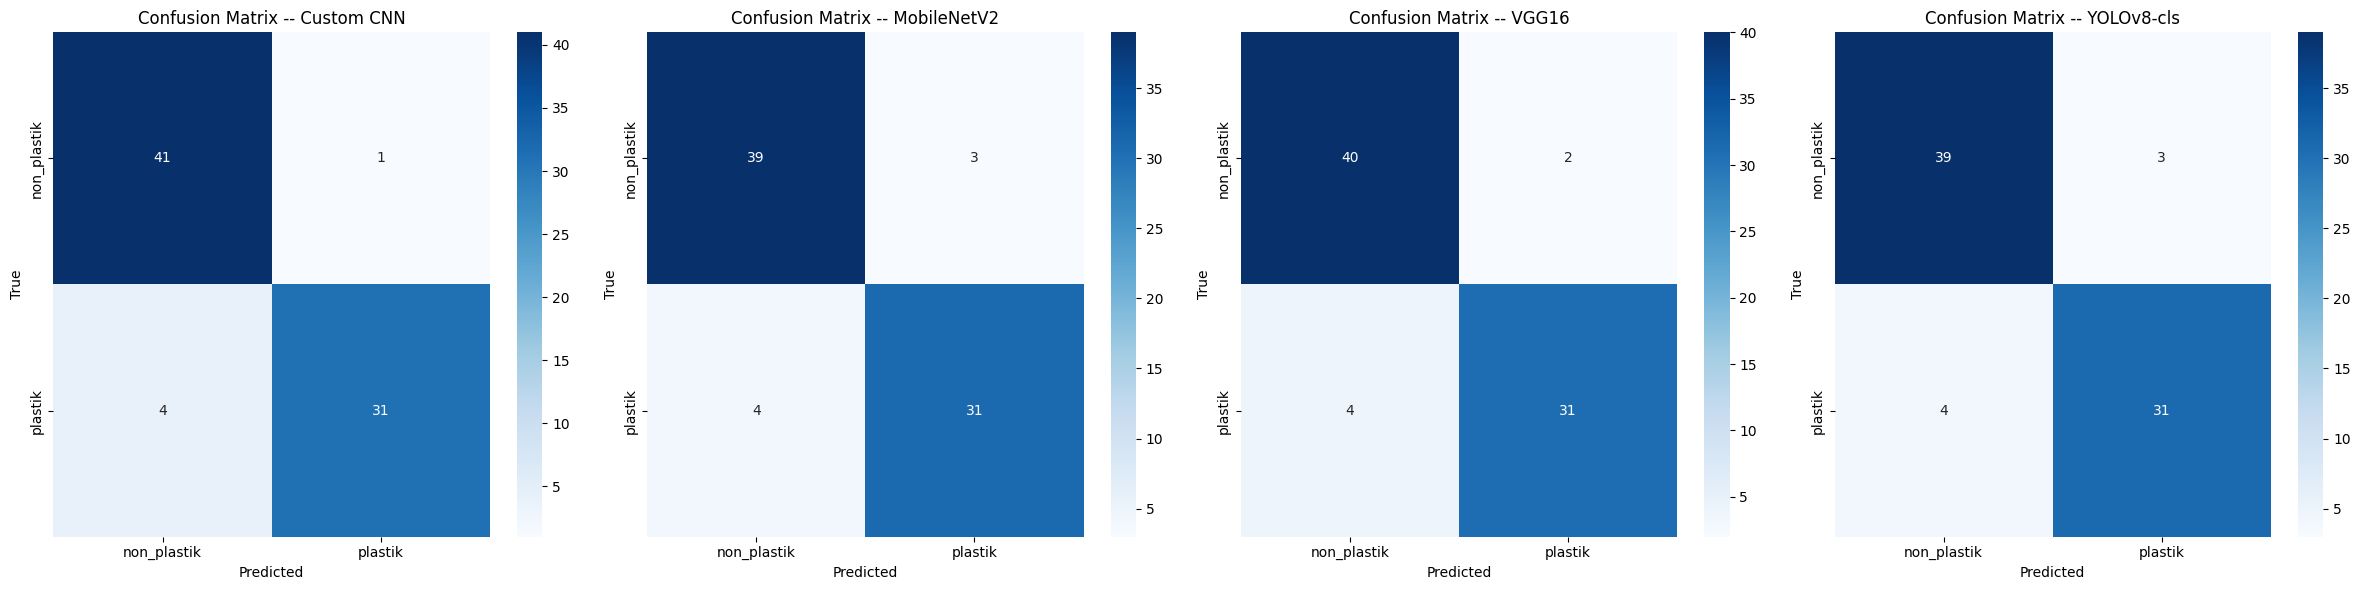

In [ ]:
# ==========================================
# VISUALISASI: CONFUSION MATRIX KEEMPAT MODEL
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
models_cm = [
    (cnn_cm, "Custom CNN"),
    (mobilenet_cm, "MobileNetV2"),
    (vgg_cm, "VGG16"),
    (yolo_cm, "YOLOv8-cls"),
]
for ax, (cm, name) in zip(axes, models_cm):
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=ax)
    ax.set_title(f"Confusion Matrix -- {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["save_dir"], "confusion_matrices_comparison.png"), dpi=150)
plt.show()


[22:38:58] WARNING: File results.csv YOLOv8 tidak ditemukan di 'runs_classify/yolov8cls_integrated/results.csv' -- kurva YOLOv8 akan dilewati.


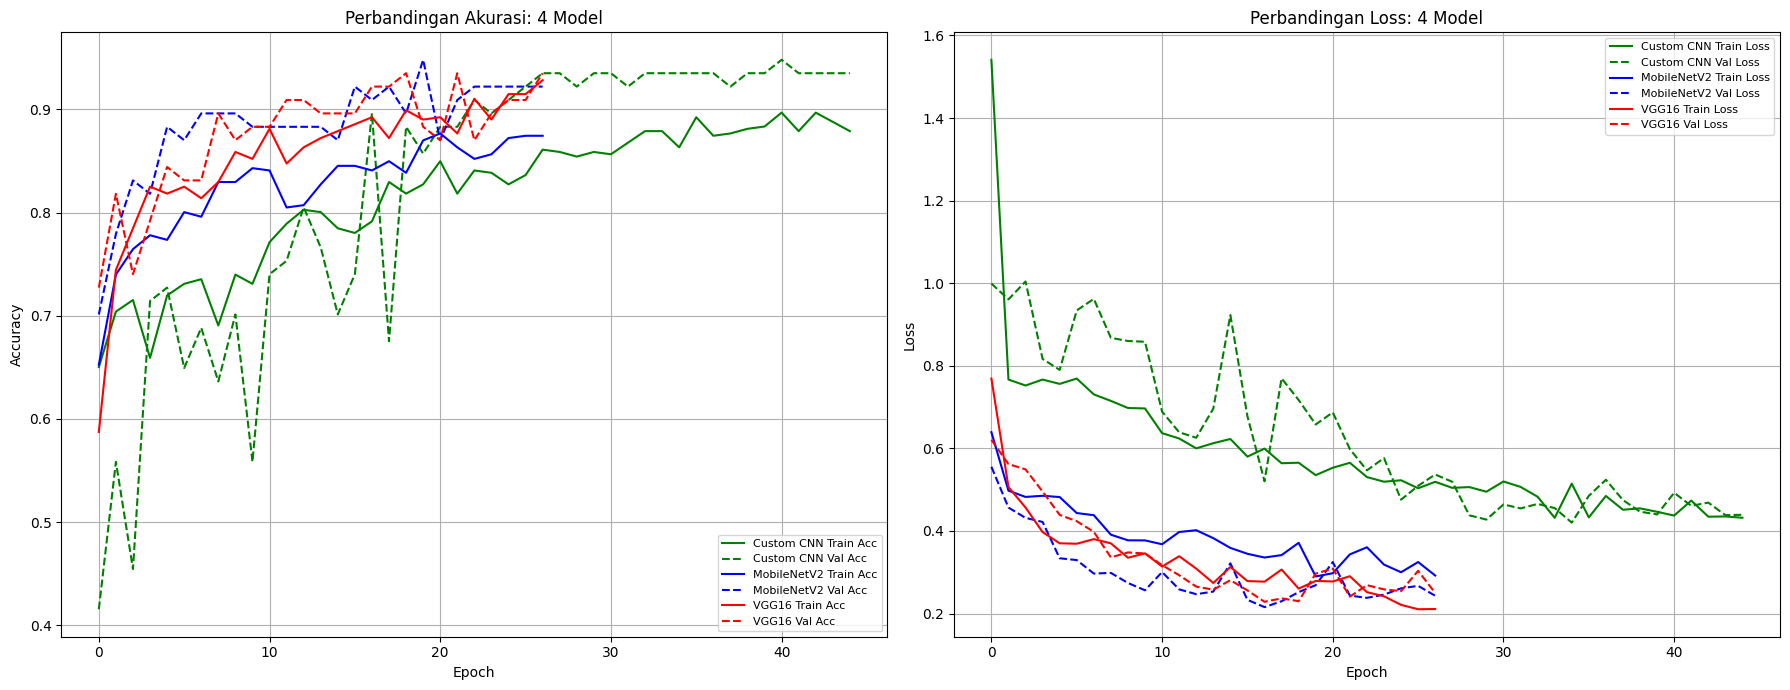

[22:39:00] INFO: Kurva gabungan 4 model disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/combined_curves_4models.png


INFO:plastik_pipeline:Kurva gabungan 4 model disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs/combined_curves_4models.png


In [ ]:
# ==========================================
# KURVA PERBANDINGAN GABUNGAN: 4 MODEL
# (1 figure, 2 panel -- akurasi & loss, keempat model dalam kurva yang sama)
# ==========================================
yolo_results_csv = os.path.join("runs_classify", "yolov8cls_integrated", "results.csv")
yolo_df = None
if os.path.exists(yolo_results_csv):
    yolo_df = pd.read_csv(yolo_results_csv).rename(columns=lambda x: x.strip())
else:
    logger.warning(f"File results.csv YOLOv8 tidak ditemukan di '{yolo_results_csv}' -- kurva YOLOv8 akan dilewati.")

keras_histories = {
    "Custom CNN": (custom_cnn_history, "green"),
    "MobileNetV2": (mobilenet_history, "blue"),
    "VGG16": (vgg_history, "red"),
}

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- Panel 1: Akurasi ---
for name, (hist, color) in keras_histories.items():
    axes[0].plot(hist.history['accuracy'], label=f'{name} Train Acc', color=color, linestyle='-')
    axes[0].plot(hist.history['val_accuracy'], label=f'{name} Val Acc', color=color, linestyle='--')
if yolo_df is not None and 'metrics/accuracy_top1' in yolo_df.columns:
    axes[0].plot(yolo_df['epoch'], yolo_df['metrics/accuracy_top1'],
                 label='YOLOv8-cls Val Top-1 Acc', color='purple', linestyle='-.')
axes[0].set_title("Perbandingan Akurasi: 4 Model")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(fontsize=8, loc='lower right'); axes[0].grid(True)

# --- Panel 2: Loss ---
for name, (hist, color) in keras_histories.items():
    axes[1].plot(hist.history['loss'], label=f'{name} Train Loss', color=color, linestyle='-')
    axes[1].plot(hist.history['val_loss'], label=f'{name} Val Loss', color=color, linestyle='--')
if yolo_df is not None:
    loss_col = 'train/loss' if 'train/loss' in yolo_df.columns else None
    if loss_col:
        axes[1].plot(yolo_df['epoch'], yolo_df[loss_col], label='YOLOv8-cls Train Loss', color='purple', linestyle='-.')
    if 'val/loss' in yolo_df.columns:
        axes[1].plot(yolo_df['epoch'], yolo_df['val/loss'], label='YOLOv8-cls Val Loss', color='purple', linestyle=':')
axes[1].set_title("Perbandingan Loss: 4 Model")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(fontsize=8, loc='upper right'); axes[1].grid(True)

plt.tight_layout()
combined_curve_path = os.path.join(CONFIG["save_dir"], "combined_curves_4models.png")
plt.savefig(combined_curve_path, dpi=150)
plt.show()
logger.info(f"Kurva gabungan 4 model disimpan ke: {combined_curve_path}")


## 11. Ringkasan

**Semua model dan hasil evaluasi tersimpan di:** `CONFIG["save_dir"]`
- `custom_cnn_model.keras`
- `mobilenet_v2_model.keras`
- `vgg16_model.keras`
- `yolov8cls_best.pt`
- `model_comparison_final.csv` (4 model)
- `confusion_matrices_comparison.png` (4 panel)
- `combined_curves_4models.png` (1 kurva berisi keempat model: akurasi + loss)

**Perbedaan utama dari notebook asli:**
1. Split train/val **identik** untuk keempat model -> perbandingan adil
2. Semua tahap kritis dibungkus **error handling eksplisit** dengan pesan actionable
3. Konversi TIF->PNG **idempoten**
4. Augmentasi diterapkan konsisten ke seluruh model Keras, dengan intensitas warna konservatif (citra true-color)
5. YOLOv8-cls memakai cosine LR scheduler + warm-up
6. **Safeguard otomatis** (cell 11a) mendeteksi jika ada 2 model dengan hasil evaluasi identik persis (indikasi bug variable-overwrite seperti kasus 3 varian MobileNetV2 sebelumnya) -- notebook akan BERHENTI dengan pesan jelas alih-alih lolos diam-diam ke tabel final
7. Peringatan otomatis jika ukuran validation set berbeda antar model (mencegah kasus tabel salah satu model dievaluasi pada jumlah sampel berbeda dari model lain)